In [25]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.feature_extraction import DictVectorizer
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt
from tqdm.auto import tqdm, trange


# Load data
data = pd.read_csv('/Users/gilleasbuigpeterson/Library/CloudStorage/OneDrive-UniversityofEdinburgh/University/5th Year/AML/Mini Project/AML_Spotify/data/Non-temporal/songs_with_super_genres.csv')


In [26]:
valid_genre_data_mask = pd.isna(data['super_genre']) == False
valid_genre_data = data[valid_genre_data_mask]
valid_genre_data

# Split the data into training set 80% and test set 20%
df_train_full, df_test = train_test_split(valid_genre_data, test_size=0.2, random_state=1)
# Further split the training set into training set 75% and validation set 25%
df_train, df_val = train_test_split(df_train_full, test_size=0.25, random_state=1)

# train_test_split() also shuffles the data randomly before splitting
# so resetting the indexes as follows:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

#  extract the target labels (the genre column) as Numpy arrays
y_train = df_train['super_genre'].values
y_val = df_val['super_genre'].values
y_test = df_test['super_genre'].values

#  drop the target label from the data
#  for now dont include one-hot enocodings for nationality and detected language, maybe come back and include one hot encodings?
del df_train['super_genre']
del df_val['super_genre']
del df_test['super_genre']
del df_train['Unnamed: 0']
del df_val['Unnamed: 0']
del df_test['Unnamed: 0']
del valid_genre_data['Unnamed: 0']

cols = valid_genre_data.select_dtypes(include=np.number).columns.tolist()
#print(cols)
#df_test.head()
#  ['Rank', 'Danceability', 'Energy', 'Speechiness', 'Acousticness', 'Instrumentalness', 'Valence', 
# 'Points (Total)', 'num_languages', 'track_popularity', 'artist_followers', 'artist_popularity', 'Loudness']

In [27]:
# change the unique genres into numerical labels by numbering the super genres from 0 to n-1, n being the total number of unique super genres
le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_val = le.transform(y_val)
y_test = le.transform(y_test)

#  gets the numeric feature columns and converts the resulting dataframe into a list of dictionaries, e.g., 'danceability': 0.5, 'energy': 0.8, ...
train_dicts = df_train[cols].to_dict(orient='records')

#  DictVectorizer will convert the list of dictionaries into a numeric vector similar to one-hot encoding for categorical variables, a dense Numpy array
#  fit_transform both learns the structure of waht features exists and converts the training data
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)

# we do a similar thing for the validation data
val_dict = df_val[cols].to_dict(orient='records')
X_val = dv.transform(val_dict)  # only transform, don't fit again

numClasses = len(le.classes_)

y_train = to_categorical(y_train, numClasses)
y_val = to_categorical(y_val, numClasses)
y_test = to_categorical(y_test, numClasses)

In [28]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

test_dict = df_test[cols].to_dict(orient='records')
X_test = dv.transform(test_dict)
X_test_scaled = scaler.transform(X_test)

In [29]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, BatchNormalization, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.regularizers import l2

num_features = X_train_scaled.shape[1]
num_classes = y_train.shape[1]  

model = Sequential([
    Dense(128, activation='relu', input_shape=(num_features,), kernel_regularizer=l2(1e-4)),
    BatchNormalization(),
    Dropout(0.3),

    Dense(64, activation='relu', kernel_regularizer=l2(1e-4)),
    BatchNormalization(),
    Dropout(0.3),

    Dense(32, activation='relu', kernel_regularizer=l2(1e-4)),
    BatchNormalization(),
    Dropout(0.2),

    Dense(num_classes, activation='softmax')
])


reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=10,
    min_lr=1e-6,
    verbose=1
)

model.compile(
    optimizer=Adam(learning_rate=1.5e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history = model.fit(
    X_train_scaled, y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=200,
    batch_size=64,
    verbose=1,
    callbacks=[reduce_lr, early_stop]
)


Epoch 1/200


/Users/gilleasbuigpeterson/Library/CloudStorage/OneDrive-UniversityofEdinburgh/University/5th Year/AML/Mini Project/AML_Spotify/venvtf/lib/python3.12/site-packages/keras/src/layers/core/dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0498 - loss: 3.5474 - val_accuracy: 0.0209 - val_loss: 3.0646 - learning_rate: 1.5000e-04
Epoch 2/200
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 903us/step - accuracy: 0.0739 - loss: 3.3369 - val_accuracy: 0.0181 - val_loss: 3.1256 - learning_rate: 1.5000e-04
Epoch 3/200
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 803us/step - accuracy: 0.1107 - loss: 3.1548 - val_accuracy: 0.0447 - val_loss: 3.0906 - learning_rate: 1.5000e-04
Epoch 4/200
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 805us/step - accuracy: 0.1447 - loss: 3.0097 - val_accuracy: 0.1066 - val_loss: 2.9893 - learning_rate: 1.5000e-04
Epoch 5/200
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 973us/step - accuracy: 0.1628 - loss: 2.9385 - val_accuracy: 0.1694 - val_loss: 2.8537 - learning_rate: 1.5000e-04
Epoch 6/200
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.1957 - loss: 2.8196 - val_accuracy: 0.2379 - val_loss: 2.7155 - learning_rate: 1.5000e-04
Epoch 7/200
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 931us/step - accuracy: 0.2329 - 

33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Improved Neural Network ROC-AUC: 0.902


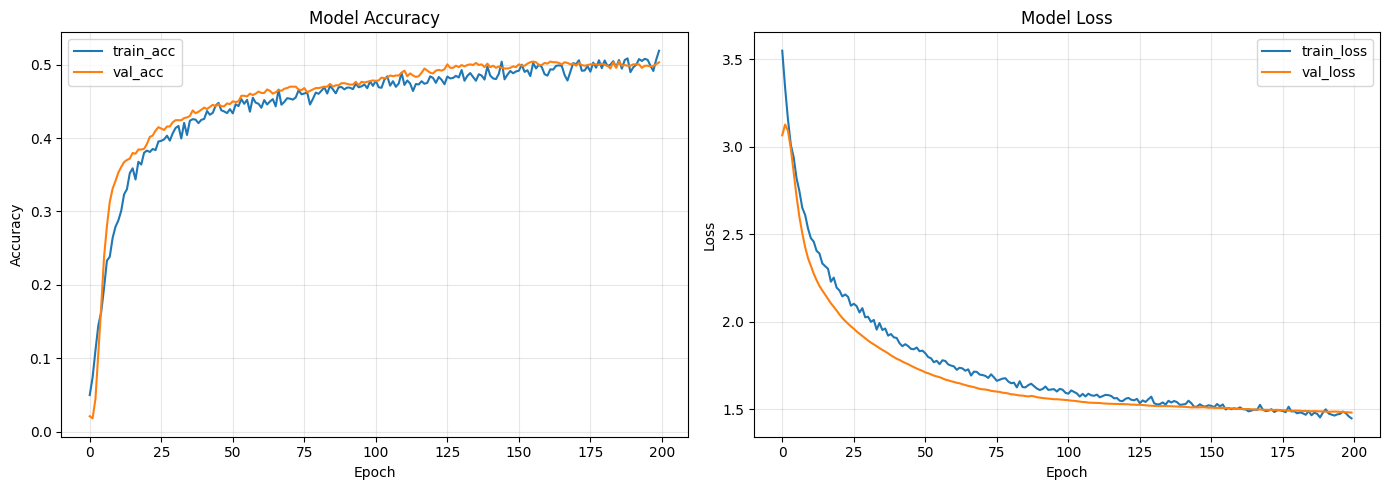

In [30]:

y_pred = model.predict(X_val_scaled)
auc = roc_auc_score(y_val, y_pred, multi_class='ovr')
print(f"Improved Neural Network ROC-AUC: {auc:.3f}")


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history.history['accuracy'], label='train_acc')
ax1.plot(history.history['val_accuracy'], label='val_acc')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.set_title('Model Accuracy')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(history.history['loss'], label='train_loss')
ax2.plot(history.history['val_loss'], label='val_loss')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.set_title('Model Loss')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()